# Classification of spoken digits with snnTorch

Developed by [Fredrik Sandin](https://www.ltu.se/staff/f/fresan-1.10646?l=en). 

In this exercise you will learn how to load and transform an event dataset of speech and develop a spiking neural network for classification of spoken digits using snnTorch. See the related tutorials and lecture material referenced in Canvas for background information.

There are 3 ***mandatory tasks*** and 1 *optional task* in this exercise.

## 1 Import libraries
Unless you have already done so, you must first install snnTorch, Tonic, and matplotlib to run this exercise.

In [ ]:
!pip install snntorch
!pip install tonic
!pip install matplotlib

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

import snntorch as snn

import tonic
from tonic import DiskCachedDataset
import tonic.transforms as transforms

import matplotlib.pyplot as plt
%matplotlib inline

/home/kaffe/.conda/envs/d7064e/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2 Loading event data with Tonic

In this exercise you will load an event-based dataset using [Tonic](https://github.com/neuromorphs/tonic), which provides some publicly available event-based vision and audio datasets and event transformations. The package is compatible with snnTorch/PyTorch.

This exercise focuses on classifying spoken digits in the [Spiking Heidelberg Digits (SHD)](https://zenkelab.org/resources/spiking-heidelberg-datasets-shd/) dataset, which includes approximately 10000 high-quality aligned studio recordings of spoken digits from 0 to 9 in both German and English language from 12 distinct speakers, out of which two speakers are only present in the test set. Each digit is represented by spikes on 700 channels which were generated using [Lauscher](https://github.com/electronicvisions/lauscher), a neuromorphic [cochlea](https://iopscience.iop.org/article/10.1088/2634-4386/ac4a83#nceac4a83s47) software model. The SHD webpage referenced above includes a leader board and the data set is presented in the following paper.

Cramer, B., Stradmann, Y., Schemmel, J., and Zenke, F. (2022).
*The Heidelberg Spiking Data Sets for the Systematic Evaluation of Spiking Neural Networks*.
IEEE Transactions on Neural Networks and Learning Systems 33, 2744–2757.
[https://doi.org/10.1109/TNNLS.2020.3044364](https://doi.org/10.1109/TNNLS.2020.3044364).

Recent work by Boeshertz et al. (https://arxiv.org/abs/2407.13534) has show that it can be preferable to use adaptive LIF neurons to generate spikes from the original Heidelberg Digits data, both w.r.t. precision and data reduciton. For those of you who want to are ambiitons and want to expand your knowledge beyond the course content, read this paper, evaluate the proposed neuron model and hypothesize why it generates better spiking data than the alternative we load in this exercise.

### 2.1 Load the training dataset and plot samples
The SHD training set includes 8156 spoken digit samples. Each digit is represented by an array of events which consists of three parameters (timestamp t, cochlea channel number x, polarity p). Plot the spike representations of five different samples of one particular digit. What are the different channels representing? What is the time duration of the patterns? Why are the patterns different although the same digit is spoken?

***Mandatory task 1:***

Extend the code below so that it plots one digit sample for each of the 20 classes in the dataset. Thus, the subplot should have 20 panels. Each panel should illustrate one sample of one particular digit. Plot different samples and analyse the variations. Are different samples of one and the same digit similar or different? Why?

In [4]:
dataset = tonic.datasets.SHD(save_to='./shd', train=True)
sensor_size = dataset.sensor_size
print("Sensor size (# channels):", sensor_size)
print("Number of training samples:", len(dataset))
print("Event representation: ", dataset.dtype)
print("Classes:", [c.decode('UTF-8') for c in dataset.classes])

Sensor size (# channels): (700, 1, 1)
Number of training samples: 8156
Event representation:  [('t', '<i8'), ('x', '<i8'), ('p', '<i8')]
Classes: ['zero', 'one', 'two', 'three', 'four', 'five', 'six', 'seven', 'eight', 'nine', 'null', 'eins', 'zwei', 'drei', 'vier', 'fuenf', 'sechs', 'sieben', 'acht', 'neun']


  zero: sample    9,  5676 events, duration 0.884 s
   one: sample    4, 10561 events, duration 0.610 s
   two: sample   40,  6604 events, duration 0.586 s
 three: sample   45,  4274 events, duration 0.580 s
  four: sample    6,  7934 events, duration 0.583 s
  five: sample    2,  4896 events, duration 0.739 s
   six: sample    8,  6144 events, duration 1.059 s
 seven: sample   62, 12023 events, duration 0.793 s
 eight: sample   73,  8927 events, duration 0.925 s
  nine: sample   13, 12889 events, duration 0.655 s
  null: sample    3, 10088 events, duration 0.783 s
  eins: sample    0,  4278 events, duration 0.701 s
  zwei: sample   14,  7000 events, duration 0.692 s
  drei: sample    1, 12118 events, duration 0.881 s
  vier: sample    7,  7071 events, duration 0.629 s
 fuenf: sample   22,  5078 events, duration 0.589 s
 sechs: sample   33,  5568 events, duration 0.801 s
sieben: sample   11,  8816 events, duration 0.774 s
  acht: sample   82,  9162 events, duration 0.735 s
  neun: samp

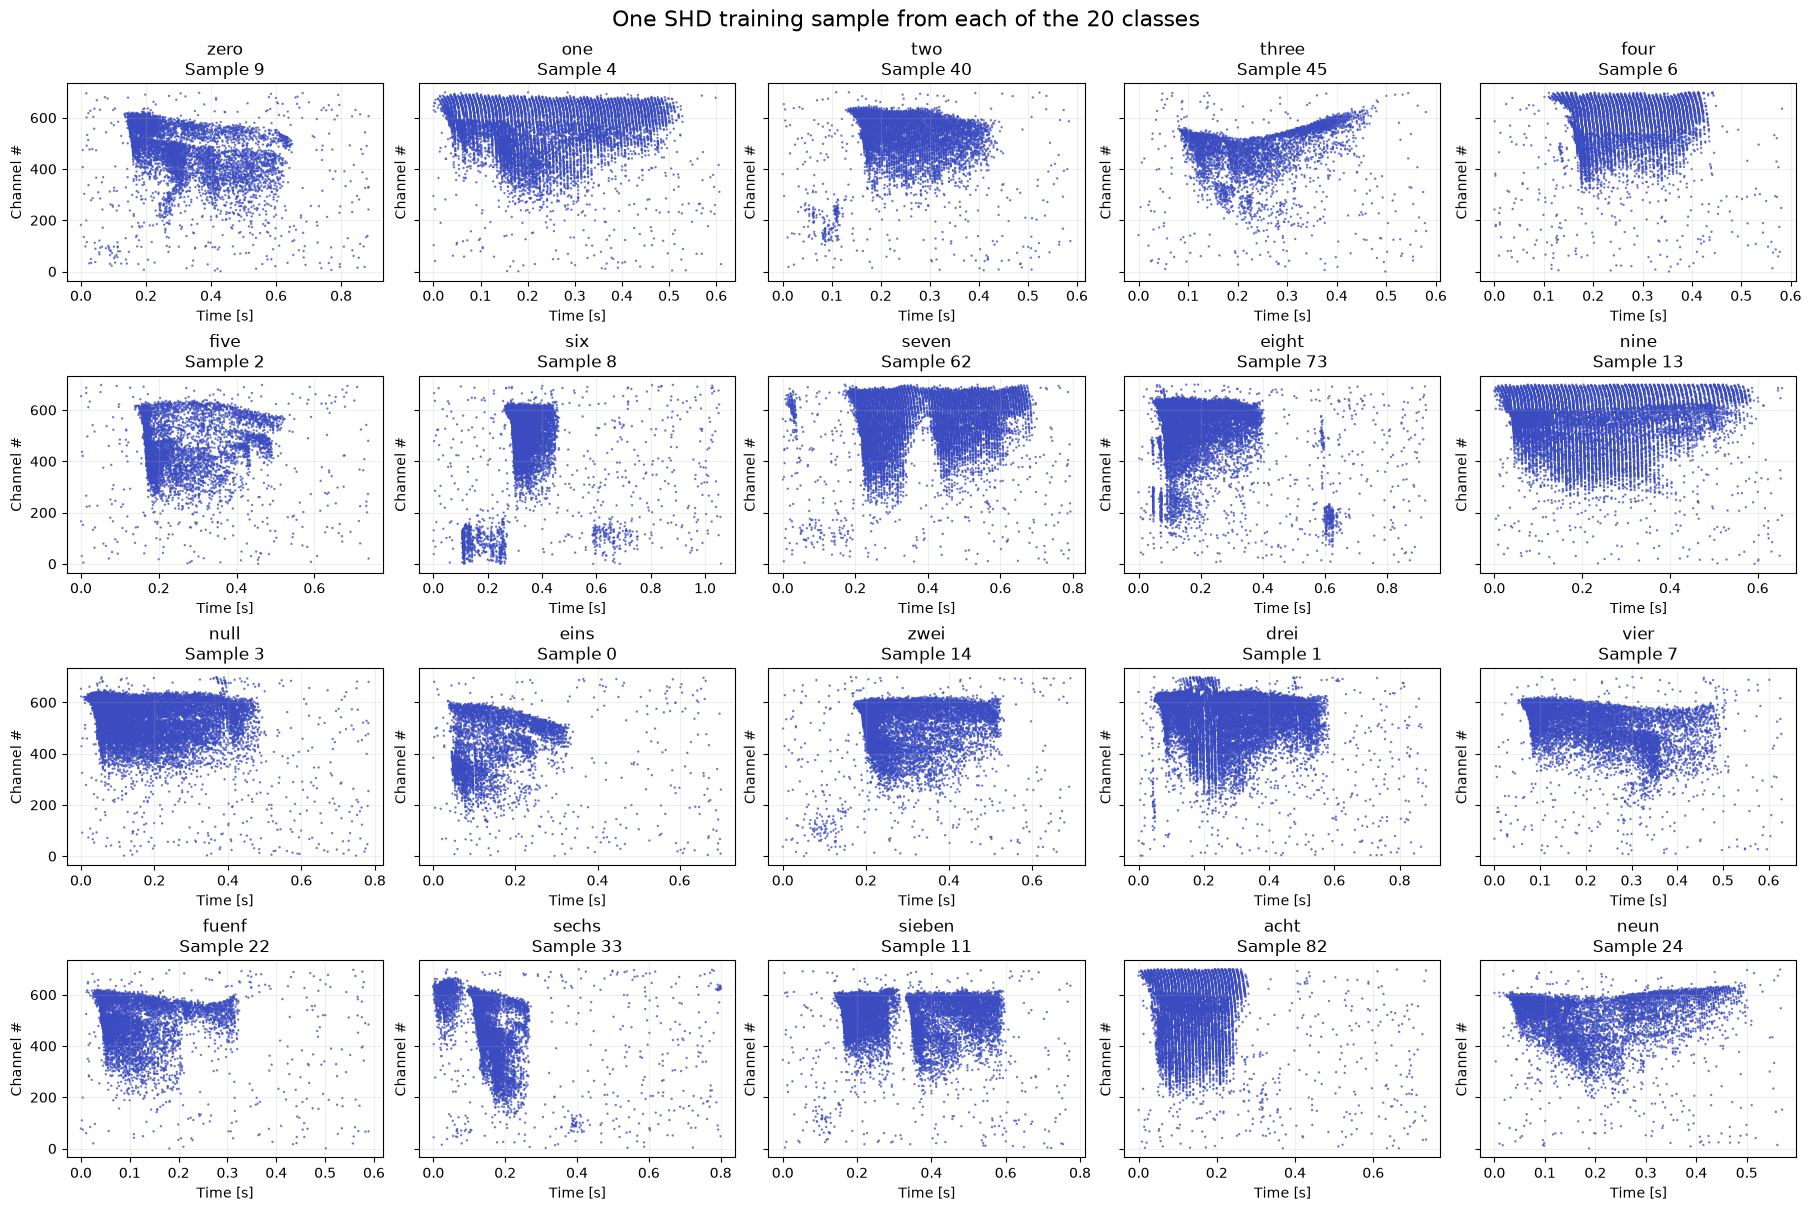

In [5]:
# Select the first sample of each of the 20 classes
class_names = [c.decode("UTF-8") for c in dataset.classes]
sample_indices = {}

for index in range(len(dataset)):
    _, label = dataset[index]
    class_id = int(label)

    if class_id not in sample_indices:
        sample_indices[class_id] = index

    # Stop once one sample has been found for every class
    if len(sample_indices) == len(class_names):
        break


# Create 20 panels arranged in 4 rows and 5 columns
fig, axs = plt.subplots(
    4,
    5,
    figsize=(18, 12),
    sharey=True,
    constrained_layout=True
)


# Plot one sample from each class
for ax, class_id in zip(axs.flat, range(len(class_names))):
    index = sample_indices[class_id]
    events, label = dataset[index]

    # Convert timestamps from microseconds to seconds
    time = 1e-6 * events["t"]
    channel = events["x"]

    ax.scatter(
        time,
        channel,
        c=events["p"],
        cmap="coolwarm",
        marker=".",
        s=2,
        alpha=0.7
    )

    ax.invert_yaxis()
    ax.set_title(f"{class_names[class_id]}\nSample {index}")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Channel #")
    ax.grid(alpha=0.2)

    print(
        f"{class_names[class_id]:>6}: "
        f"sample {index:4d}, "
        f"{len(events):5d} events, "
        f"duration {time.max():.3f} s"
    )


fig.suptitle(
    "One SHD training sample from each of the 20 classes",
    fontsize=16
)

plt.show()

So the code above plots out the first data sample for every class. It does this by creating a a empty dictionary and as soon as it encounters the first sample of a "new" class it maps it in the dictionary by converting the class label into a integer. When it starts to plot it retrieves the saved index for each class and plots the lowest index occurence of every class in the data set. 

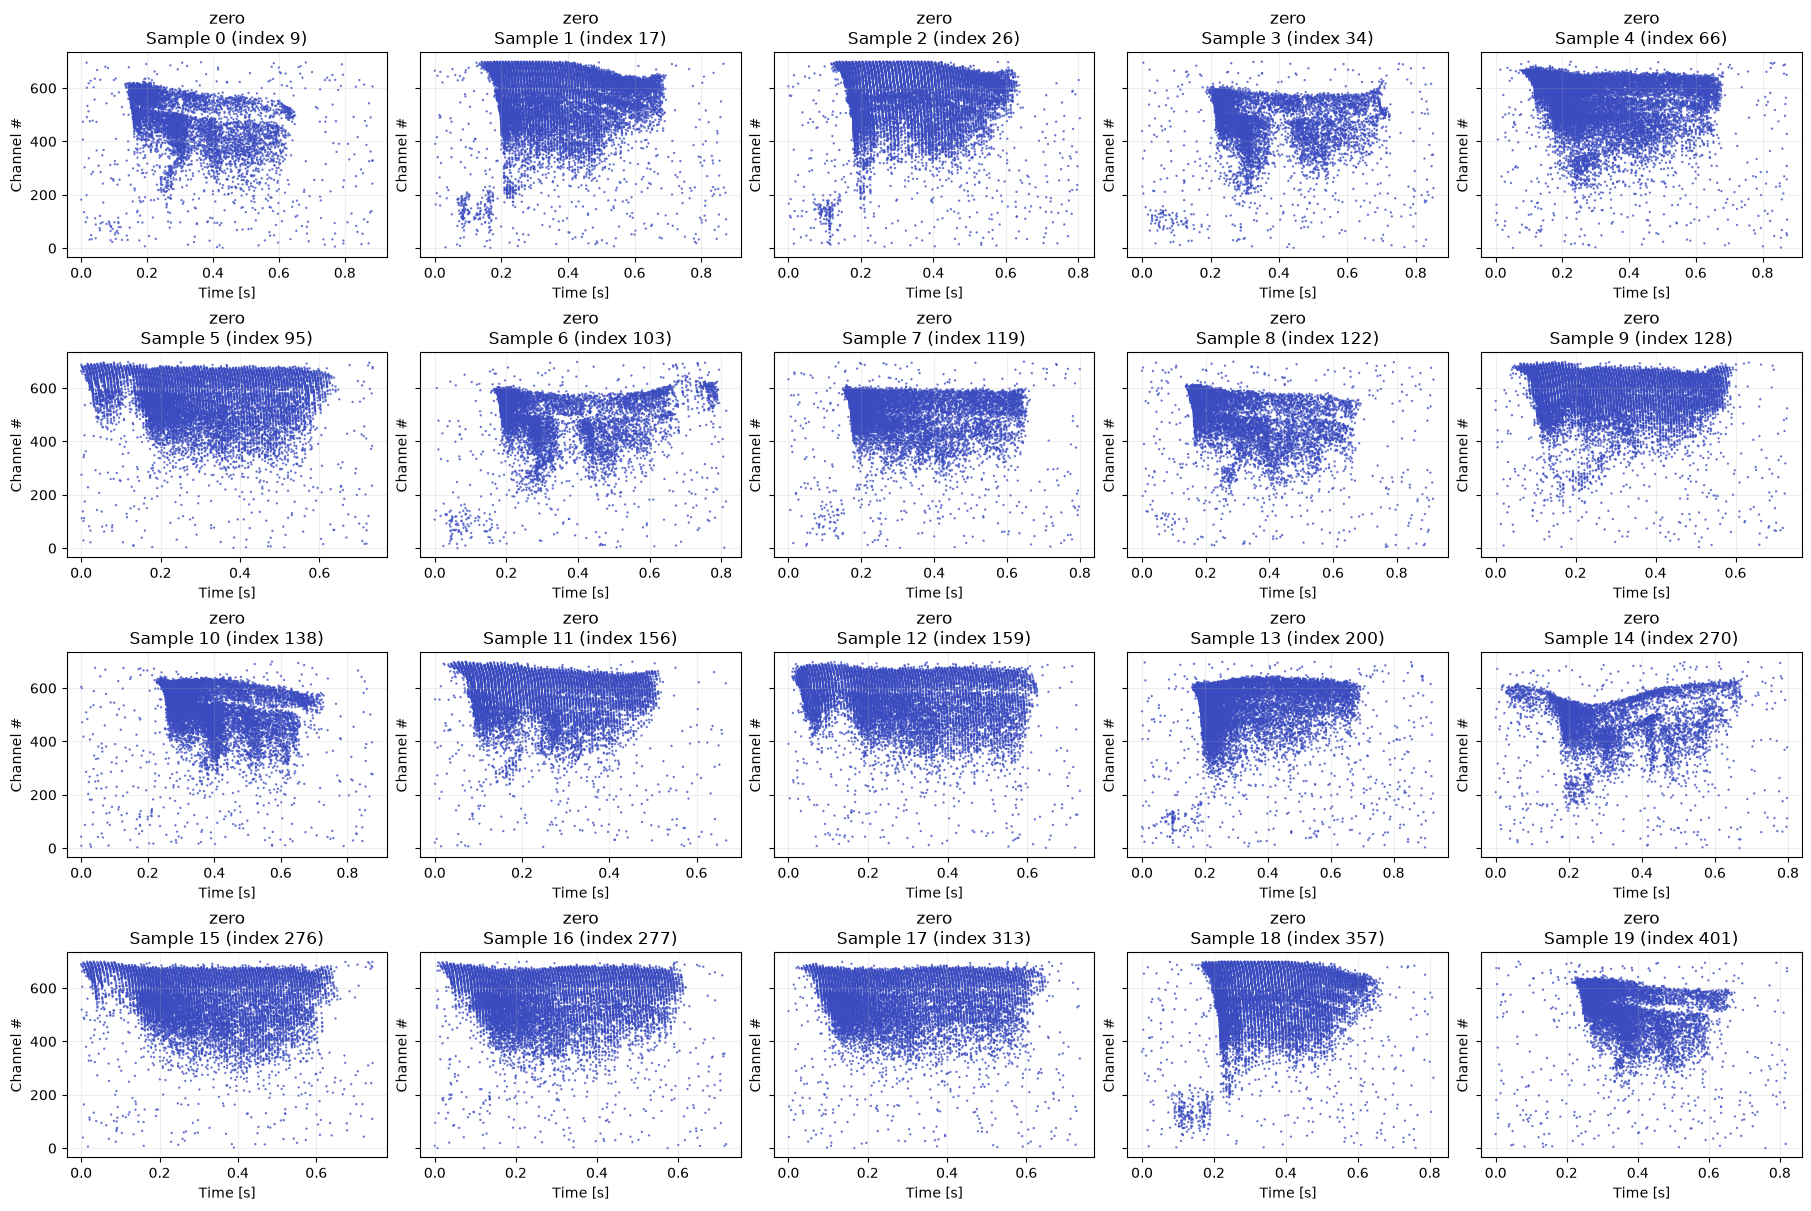

In [8]:
# Compare 20 samples from the same class
class_id = 0    # Change this to select another class
num_samples = 20

# Find the first 20 dataset indices belonging to the selected class
class_sample_indices = []
for index in range(len(dataset)):
    _, label = dataset[index]
    if int(label) == class_id:
        class_sample_indices.append(index)
        if len(class_sample_indices) == num_samples:
            break

if len(class_sample_indices) < num_samples:
    raise ValueError(
        f"Class {class_id} contains only {len(class_sample_indices)} samples; "
        f"cannot plot {num_samples}."
    )

fig, axs = plt.subplots(
    4,
    5,
    figsize=(18, 12),
    sharey=True,
    constrained_layout=True
)

# Plot samples 0-19 from the selected class
for sample_number, (ax, index) in enumerate(
    zip(axs.flat, class_sample_indices)
):
    events, label = dataset[index]

    # Convert timestamps from microseconds to seconds
    time = 1e-6 * events["t"]
    channel = events["x"]

    ax.scatter(
        time,
        channel,
        c=events["p"],
        cmap="coolwarm",
        marker=".",
        s=2,
        alpha=0.7
    )

    ax.invert_yaxis()
    ax.set_title(f"{class_names[class_id]}\nSample {sample_number} (index {index})")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Channel #")
    ax.grid(alpha=0.2)



## Same class, different samples

The reason for why there is a difference between the same class with different samples is due to the different samples being inherently different. But seeing the raster spike plots you can observe that they kind of follow the same structure, but since things like speaking speed, pronouciation etc can vary, it results in different results.

### End of Mandatory 1
-----------------------------------------------



Digit 33 is represented by 5568 events
Digit 35 is represented by 8034 events
Digit 109 is represented by 5620 events
Digit 136 is represented by 5243 events
Digit 147 is represented by 6263 events


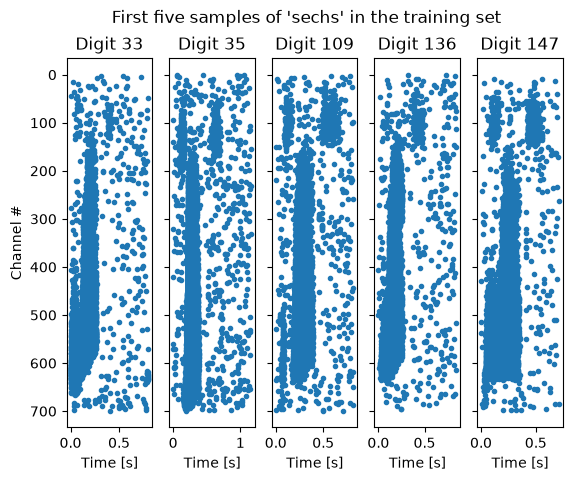

In [9]:
index = 0
samples = 0
digit = "sechs"
fig, axs = plt.subplots(1,5, sharey=True)
fig.suptitle(f"First five samples of '{digit}' in the training set")
axs[0].set_ylabel("Channel #")
while samples < len(axs):
    events, label = dataset[index]
    if dataset.classes[label].decode('UTF-8') == digit:
        axs[samples].scatter(1e-6*events['t'], events['x'], marker=".")
        axs[samples].invert_yaxis()
        axs[samples].set_title(f"Digit {index}")
        axs[samples].set_xlabel("Time [s]")
        print(f"Digit {index} is represented by {len(events)} events")
        samples += 1
    index += 1

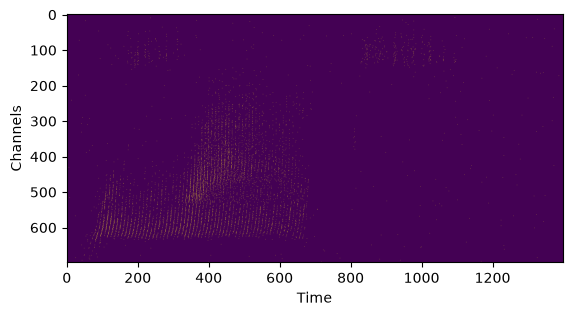

In [10]:
# Tonic provides an event plotting function that can also be used (Time in ms), which rasterizes the events and displays the result with imshow().
tonic.utils.plot_event_grid(events)

### 2.2 Downsample the digits and create a dataloader

Now you are familiar with the samples in the dataset. It is time to prepare the digits in a format that is suitable for snnTorch experiments on a PC. To obtain state-of-the-art results we would need to keep a high spatial and temporal resolution of the digits. However, with 700 input channels the simulations would take far too long time if we process the full-resolution digits.

We can choose a set of transforms to apply to our data before feeding it to an SNN. Here we [Downsample](https://tonic.readthedocs.io/en/main/autoapi/tonic/transforms/index.html#tonic.transforms.Downsample) the events to 70 channels instead of 700, which reduces the dimension of the resulting tensor representations. Furthermore, we use the [toFrame](https://tonic.readthedocs.io/en/main/generated/tonic.transforms.ToFrame.html#tonic.transforms.ToFrame) transformation with time-binning over 10000 microseconds, which results in a sequence of 10-millisecond long frames with 70 channels each.
 
To speed up dataloading, we can make use of disk caching and batching. That means that once the files are loaded from the original dataset they are written to the disk. Because the event arrays have different lengths, we are going to use a collation function tonic.collation.PadTensors() that will pad shorter recordings to ensure all tensors in a batch have the same dimensions.

If you need to refresh basic machine learning concepts such as "batch" and "training set" a good reference is the [Deep Learning](https://www.deeplearningbook.org/) book, which is part of the course literature in the [D7046E Neural networks and learning machines](https://www.ltu.se/edu/course/D70/D7046E/D7046E-Neuronnat-och-larande-maskiner-1.183276?kursView=kursplan&l=en) course.

In [ ]:
# imports for Delete cache folder if it exists

from pathlib import Path
import shutil

batch_size = 16 # Keeping this small for clarity of the examples below, you may need to increase it later
cache_path = Path("./data/cache/shd/train")

# Self explanatory
if cache_path.exists():
    rmCache(cache_path)
    pass
# OBS: You must first delete the cache files before running this with new parameters/transforms, otherwise there is no effect of modified hyperparameters


trainset = tonic.datasets.SHD(
    save_to='./data',
    train=True,
    transform=transforms.Compose([
        transforms.Downsample(sensor_size=sensor_size, spatial_factor=0.1), # 70 channels
        transforms.ToFrame(sensor_size=(70,1,1),time_window=10000) # us to 10 ms
    ])
)

cached_trainset = DiskCachedDataset(
    trainset,
    cache_path='./data/cache/shd/train',
    transform=torch.from_numpy
)

trainloader = DataLoader(
    cached_trainset,
    batch_size=batch_size, 
    collate_fn=tonic.collation.PadTensors()
)

trainiter = iter(trainloader)

# Function that returns the next batch from the training set
def load_training_batch():
    events, targets = next(trainiter)    
    # snnTorch torch uses time-first tensors, which means [time x batch_size x feature_dimensions].
    # Convert from the default [batch_size x time x 1 x channels] frame representation in the dataset:
    events = events.transpose(0,1).squeeze()
    return (events, targets)

def rmCache(cache_path):
    shutil.rmtree(cache_path)                       # Deleted cache
    cache_path.mkdir(parents=True, exist_ok=True)   # Recreated cache folder

test


### 2.3 Load one batch and visualize the downsampled digits 

Shape of batch with 16 digits:  torch.Size([105, 16, 70])


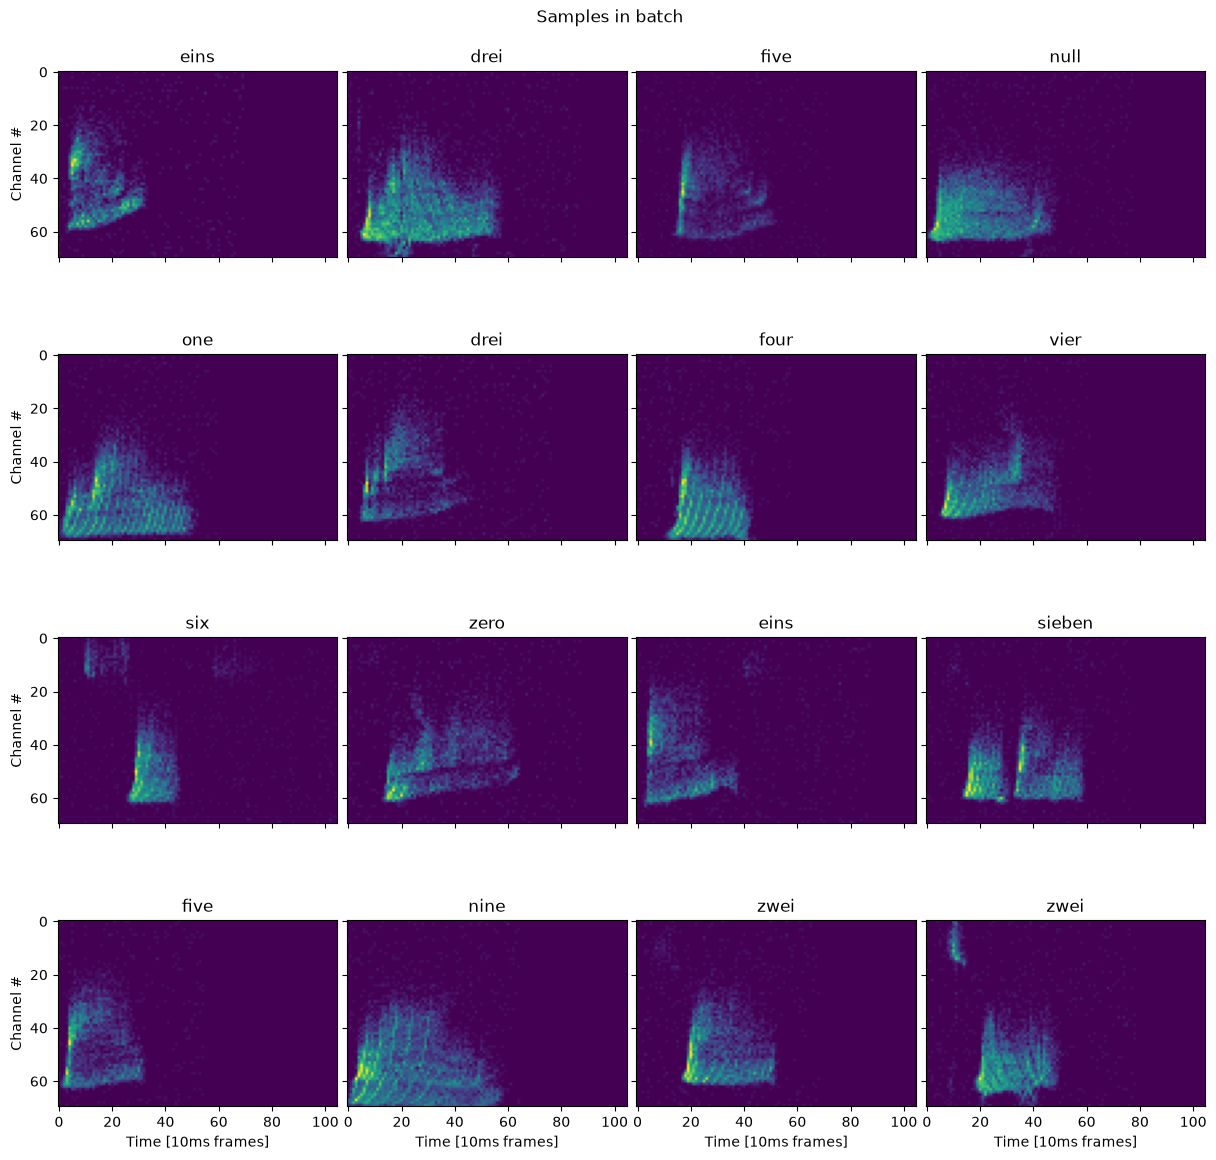

In [23]:
# Enable plotting of tensors with matplotlib
torch.Tensor.ndim = property(lambda self: len(self.shape))

events, target = load_training_batch()
print(f"Shape of batch with {batch_size} digits: ", events.shape)

fig,axs = plt.subplots(4,4,figsize=(12,12),sharex=True, sharey=True)
fig.suptitle(f"Samples in batch")

for i in range(4):
    axs[i,0].set_ylabel('Channel #')
    for j in range(4):
        index = i*4+j
        tensor = events[:,index,:].transpose(0,1)
        axs[i,j].imshow(tensor)
        axs[i,j].set_title(trainset.classes[target[index]].decode('UTF-8'))
        if i==3:
            axs[i,j].set_xlabel('Time [10ms frames]')
plt.tight_layout(pad=0)
plt.show()

## 3 Processing of digits with a feed-forward SNN

The following is an adaptation of the feed-forward SNN example presented in the snnTorch [tutorial 3](https://snntorch.readthedocs.io/en/latest/tutorials/tutorial_3.html). The following code implements a feed-forward SNN that processes the downsampled digits in the SHD trainset visualized above. The code illustrates the principle of how to
   * Run a basic SNN simulation with SHD input data
   * Visualize the resulting spikes in the hidden and output layer

### 3.1 Run SNN simulation over timesteps in the batch

***Mandatory task 2:*** How much longer is the simulation time of one forward pass if the original number of channels (700) in the dataset is used? Does the time-binning introduced by the toFrame transformation reduce simulation time? Run simulations to validate your analysis.

In [8]:
num_timesteps = events.shape[0]     # Number of timesteps in the longest-duration digit
num_samples = events.shape[1]       # Number of digits in batch
num_channels = events.shape[2]      # Number of channels in downsampled digits
num_classes = len(trainset.classes)

# SNN hyperparameters
beta = 0.95
num_inputs = num_channels
num_outputs = num_classes
hidden_sizefac = 2        # Size of hidden layer in relation to size of input layer

# Define first hidden layer and input connections
fc1 = nn.Linear(num_inputs, hidden_sizefac*num_channels)
lif1 = snn.Leaky(beta=beta)

# Define output layer with inputs from hidden layer
fc2 = nn.Linear(hidden_sizefac*num_channels, num_outputs)
lif2 = snn.Leaky(beta=beta)

# Initialize neuron states
mem1 = lif1.init_leaky()
mem2 = lif2.init_leaky()

# Placeholders for outputs
mem2_rec = []
spk1_rec = []
spk2_rec = []

# Run network simulation over all timesteps in the input tensor
for step in range(num_timesteps):

    cur1 = fc1(events[step,:,:])  # post-synaptic current to hidden <-- spk_in x weight
    spk1, mem1 = lif1(cur1, mem1) # mem1[t+1] <--post-syn current contrib + decayed membrane
    cur2 = fc2(spk1)              # post-synaptic current to output neurons
    spk2, mem2 = lif2(cur2, mem2) # output

    # Store states for analysis and plotting
    spk1_rec.append(spk1)
    spk2_rec.append(spk2)
    mem2_rec.append(mem2)

# Convert lists to tensors
mem2_rec = torch.stack(mem2_rec)
spk1_rec = torch.stack(spk1_rec)
spk2_rec = torch.stack(spk2_rec)

print("Hidden spikes shape", spk1_rec.shape)
print("Output spikes shape", spk2_rec.shape)
print("Output potential shape:", mem2_rec.shape)

Hidden spikes shape torch.Size([105, 16, 140])
Output spikes shape torch.Size([105, 16, 20])
Output potential shape: torch.Size([105, 16, 20])


In [ ]:
# Plot activity of hidden neurons for each input digit in the batch
s = spk1_rec.detach().numpy()
fig,axs = plt.subplots(4,4,figsize=(8,12),sharex=True,sharey=True)
fig.suptitle(f"Hidden neuron spikes")
fig.tight_layout()
for i in range(4):
    axs[i,0].set_ylabel('Hidden neuron #')
    for j in range(4):
        index = i*4+j
        tensor = s[:,index,:].squeeze().transpose(1,0)
        axs[i,j].imshow(tensor)
        axs[i,j].set_title(trainset.classes[target[index]].decode('UTF-8'))
        if i==3:
            axs[i,j].set_xlabel('Time [10ms frames]')
plt.show()

In [ ]:
# Plot activity of output neurons for each input digit in the batch
s = spk2_rec.detach().numpy()
fig,axs = plt.subplots(4,4,figsize=(8,4),sharex=True,sharey=True)
fig.suptitle(f"Output neuron spikes")
fig.tight_layout()
for i in range(4):
    axs[i,0].set_ylabel('Output #')
    for j in range(4):
        index = i*4+j
        tensor = s[:,index,:].squeeze().transpose(1,0)
        axs[i,j].imshow(tensor)
        axs[i,j].set_title(trainset.classes[target[index]].decode('UTF-8'))
        if i==3:
            axs[i,j].set_xlabel('Time [10ms frames]')
plt.show()

## 4 Train an SNN to classify the digits

***Mandatory task 3:***

Based on your understanding of the code above and the [snnTorch tutorial 5](https://snntorch.readthedocs.io/en/latest/tutorials/tutorial_5.html) (and any other documented functions in snnTorch) that you think are required, develop and train a feed-forward SNN for classification of the 20 different digits in the SHD dataset.

The goal is that after training the 20 output neurons of the networks should differentiate between the 20 different digits in the training set, in the sense that for each target/class one particular output neuron is more likely to fire and/or fires with a higher spikerate than the other 19 neurons.

Note that you cannot directly copy the example in tutorial 5 because the SHD digits have varying duration in time (while the MNIST samples in the tutorial have fixed dimensionality and consequently the inputs could be flattened to vectors in that case). Here you need to consider and optimize the response of the output neurons over time when each digit is presented to the network.

Plot the ***loss curve*** from the start until the end of training (over all "epochs"). The goal is that the loss should decrease and eventually converge or fluctuate at a low value. What is the ***accuracy of your classifier*** before and after training? Plot a ***confusion matrix***, what are the weaknesses/strengths of your classifier based on the result?

***Hints:***

Use the discussion forum for exercises in Canvas if you get stuck. Share what you have learned and what question you have.

In [298]:
# Develop and train SNN classifier

## 5 Test and improve the trained SNN

***Optional task:***

Test and improve the accuracy of your SNN classifier. How high accuracy can you achieve? How close to the SHD leader board is your result? Can you benefit from spiking CNNs, LSTMSs, ...?


In [ ]:
testset = tonic.datasets.SHD(save_to='./data', train=False)

cached_testset = DiskCachedDataset(testset, transform=...

testloader = DataLoader(cached_testset, ...

## References

The Heidelberg Spiking Data Sets for the Systematic Evaluation of Spiking Neural Networks;
[https://doi.org/10.1109/TNNLS.2020.3044364](https://doi.org/10.1109/TNNLS.2020.3044364).

Surrogate Gradient Learning in Spiking Neural Networks: Bringing the Power of Gradient-Based Optimization to Spiking Neural Networks; [https://doi.org/10.1109/MSP.2019.2931595](https://doi.org/10.1109/MSP.2019.2931595).

Training Spiking Neural Networks Using Lessons From Deep Learning; [https://doi.org/10.1109/JPROC.2023.3308088](https://doi.org/10.1109/JPROC.2023.3308088).